##Detección de cardiopatía

In [ ]:
#Importamos librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, auc
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from google.colab import drive
# Ignorar warnings
import warnings
warnings.filterwarnings('ignore')


In [ ]:
#Cargamos la data de Cleveland
# Montamos Google Drive
from google.colab import drive # This should be at the top with other imports.
drive.mount('/content/drive')

# Ajustar la ruta al archivo en Google Drive
file_path = '/content/drive/My Drive/Data Science/6. Modelos avanzados y redes neuronales/Desafío2/processed.cleveland.data'

# Lista de nombres de las columnas según la descripción del dataset
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
                'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

# Cargar el archivo .data delimitado por comas (CSV estándar) utilizando file_path
# Se cambió 'processed_cleveland.data' por file_path para leer desde la ubicación correcta
dfCL = pd.read_csv(file_path, delimiter=',', header=None, names=column_names)

# Mostrar las primeras filas del DataFrame
print(dfCL.head())

Mounted at /content/drive
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca thal  num  
0    3.0  0.0  6.0    0  
1    2.0  3.0  3.0    2  
2    2.0  2.0  7.0    1  
3    3.0  0.0  3.0    0  
4    1.0  0.0  3.0    0  


In [ ]:
#Cargamos la data de Hungarian

drive.mount('/content/drive')

# Ajustar la ruta al archivo en Google Drive
file_path = '/content/drive/My Drive/Data Science/6. Modelos avanzados y redes neuronales/Desafío2/processed.hungarian.data'

# Lista de nombres de las columnas según la descripción del dataset
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
                'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

# Cargar el archivo .data delimitado por comas (CSV estándar) utilizando file_path
# Se cambió 'processed_cleveland.data' por file_path para leer desde la ubicación correcta
dfH = pd.read_csv(file_path, delimiter=',', header=None, names=column_names)

# Mostrar las primeras filas del DataFrame
print(dfH.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   age  sex  cp trestbps chol fbs restecg thalach exang  oldpeak slope ca  \
0   28    1   2      130  132   0       2     185     0      0.0     ?  ?   
1   29    1   2      120  243   0       0     160     0      0.0     ?  ?   
2   29    1   2      140    ?   0       0     170     0      0.0     ?  ?   
3   30    0   1      170  237   0       1     170     0      0.0     ?  ?   
4   31    0   2      100  219   0       1     150     0      0.0     ?  ?   

  thal  num  
0    ?    0  
1    ?    0  
2    ?    0  
3    6    0  
4    ?    0  


In [ ]:
#Cargamos la data de Switzerland
drive.mount('/content/drive')

# Ajustar la ruta al archivo en Google Drive
file_path = '/content/drive/My Drive/Data Science/6. Modelos avanzados y redes neuronales/Desafío2/processed.switzerland.data'

# Lista de nombres de las columnas según la descripción del dataset
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
                'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

# Cargar el archivo .data delimitado por comas (CSV estándar) utilizando file_path
# Se cambió 'processed_cleveland.data' por file_path para leer desde la ubicación correcta
dfS = pd.read_csv(file_path, delimiter=',', header=None, names=column_names)

# Mostrar las primeras filas del DataFrame
print(dfS.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   age  sex  cp trestbps  chol fbs restecg thalach exang oldpeak slope ca  \
0   32    1   1       95     0   ?       0     127     0      .7     1  ?   
1   34    1   4      115     0   ?       ?     154     0      .2     1  ?   
2   35    1   4        ?     0   ?       0     130     1       ?     ?  ?   
3   36    1   4      110     0   ?       0     125     1       1     2  ?   
4   38    0   4      105     0   ?       0     166     0     2.8     1  ?   

  thal  num  
0    ?    1  
1    ?    1  
2    7    3  
3    6    1  
4    ?    2  


1. Carga los datos de los tres archivos unidos en un DataFrame, y prepáralos
considerando las siguientes etapas:

In [ ]:
# Unir los tres archivos en un solo DataFrame
df = pd.concat([dfCL, dfH, dfS], ignore_index=True)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,70.0,1.0,4.0,115,0,0,1,92,1,0,2,?,7,1
716,70.0,1.0,4.0,140,0,1,0,157,1,2,2,?,7,3
717,72.0,1.0,3.0,160,0,?,2,114,0,1.6,2,2,?,0
718,73.0,0.0,3.0,160,0,0,1,121,0,0,1,?,3,1


In [ ]:
# Mostrar los valores nulos por columna en porcentaje
missing_percent = df.isnull().mean() * 100
print("Porcentaje de valores ausentes por columna:")
print(missing_percent)

Porcentaje de valores ausentes por columna:
age         0.0
sex         0.0
cp          0.0
trestbps    0.0
chol        0.0
fbs         0.0
restecg     0.0
thalach     0.0
exang       0.0
oldpeak     0.0
slope       0.0
ca          0.0
thal        0.0
num         0.0
dtype: float64


a. asigna a la variable objetivo num un cero cuando su valor es cero, y un 1 en
otro caso. Muestra la cantidad de valores ausente por atributo. Procésalos
considerando los siguientes criterios:

In [ ]:
# Procesar la variable objetivo num: asignar 0 cuando es 0, y 1 cuando es mayor a 0
df['num'] = df['num'].apply(lambda x: 0 if x == 0 else 1)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


i. si el atributo presenta un porcentaje de valores ausentes mayor a 25%, entonces descartamos ese atributo.

In [ ]:
threshold = 25
df_filtered = df.loc[:, missing_percent <= threshold]

ii. para los atributos con valores ausentes menores al 25% se deben
rellenar con el valor promedio del atributo de acuerdo a la clase, es
decir, los valores ausentes para los cuales num=0 se deben rellenar
con el promedio de los valores presentes para los cuales num=0.

In [ ]:
df_num_0 = df_filtered[df_filtered['num'] == 0]
df_num_1 = df_filtered[df_filtered['num'] == 1]

iii. Para las variables categóricas, los valores a asignar (promedio) deben
ser aproximados al valor entero más cercano.

In [ ]:
  # Función para rellenar valores numéricos
def fill_na_by_class(df, column):
    mean_num_0 = df_num_0[column].mean()
    mean_num_1 = df_num_1[column].mean()

    # Si la columna es categórica, redondeamos los valores al entero más cercano
    if df[column].dtype == 'int64' or df[column].dtype == 'object':
        mean_num_0 = round(mean_num_0)
        mean_num_1 = round(mean_num_1)

    # Rellenar los valores ausentes
    df.loc[df['num'] == 0, column] = df.loc[df['num'] == 0, column].fillna(mean_num_0)
    df.loc[df['num'] == 1, column] = df.loc[df['num'] == 1, column].fillna(mean_num_1)

# Aplicar la función a cada columna que tenga valores ausentes (menos del 25%)
for col in df_filtered.columns:
    if df_filtered[col].isnull().sum() > 0:
        fill_na_by_class(df_filtered, col)

In [ ]:
#verificamos que la variabe num tenga valores entre 0 y 1
df_filtered['num'] = df_filtered['num'].apply(lambda x: 0 if x == 0 else 1)

# Mostrar el DataFrame final
print(df_filtered.head())

    age  sex   cp trestbps   chol  fbs restecg thalach exang oldpeak slope  \
0  63.0  1.0  1.0    145.0  233.0  1.0     2.0   150.0   0.0     2.3   3.0   
1  67.0  1.0  4.0    160.0  286.0  0.0     2.0   108.0   1.0     1.5   2.0   
2  67.0  1.0  4.0    120.0  229.0  0.0     2.0   129.0   1.0     2.6   2.0   
3  37.0  1.0  3.0    130.0  250.0  0.0     0.0   187.0   0.0     3.5   3.0   
4  41.0  0.0  2.0    130.0  204.0  0.0     2.0   172.0   0.0     1.4   1.0   

    ca thal  num  
0  0.0  6.0    0  
1  3.0  3.0    1  
2  2.0  7.0    1  
3  0.0  3.0    0  
4  0.0  3.0    0  


b. Construye variables dummies para las variables discretas con tres o más
categorías.

Para este caso consideraremos las siguientes variables:

- cp: Tipo de dolor torácico (4 categorías: 1, 2, 3, 4).
- restecg: Medición electrocardiográfica en reposo (3 categorías: 0, 1, 2).
- slope: Pendiente del segmento ST (3 categorías: 1, 2, 3).
- thal: Tipo de defecto cardíaco (3 categorías: 3, 6, 7).

In [ ]:
print(df_filtered['cp'].value_counts())
print(df_filtered['restecg'].value_counts())
print(df_filtered['slope'].value_counts())
print(df_filtered['thal'].value_counts())

cp
4.0    365
2.0    160
3.0    157
1.0     38
Name: count, dtype: int64
restecg
0      320
0.0    151
2.0    148
1       82
2       13
1.0      4
?        2
Name: count, dtype: int64
slope
?      207
2      152
1.0    142
2.0    140
1       45
3.0     21
3       13
Name: count, dtype: int64
thal
?      320
3.0    166
7.0    117
7       53
3       26
6       20
6.0     18
Name: count, dtype: int64


In [ ]:
# Reemplazar '?' por NaN
df.replace('?', np.nan, inplace=True)

# Convertir las columnas 'cp', 'restecg', 'slope', y 'thal' a tipo numérico (de float a int si es necesario)
# Esto también convertirá automáticamente valores como 1.0 a 1, y 7.0 a 7

col_redondeadas = ['cp', 'restecg', 'slope', 'thal']
df_filtered[col_redondeadas] = df_filtered[col_redondeadas].apply(pd.to_numeric, errors='coerce')

# Después de hacer la conversión, rellena con el valor entero más cercano para los valores faltantes
df_filtered[col_redondeadas] = df_filtered[col_redondeadas].round(0).astype('Int64')

# Verificar el resultado
print(df_filtered[col_redondeadas].value_counts())

cp  restecg  slope  thal
4   0        2      7       42
    2        2      7       28
3   0        1      3       25
2   0        1      3       20
4   2        2      3       16
    0        1      7       16
             2      3       16
3   2        1      3       15
    0        2      3       14
4   2        1      3       13
    0        1      3       11
             2      6       11
2   2        1      3       10
3   0        2      7       10
4   2        1      7       10
3   2        2      7        8
2   2        2      3        6
3   2        2      3        6
4   1        2      7        5
1   2        1      3        5
3   0        1      7        5
4   2        2      6        5
             3      7        5
2   0        1      7        4
1   2        2      3        4
4   0        3      7        3
    1        1      7        3
3   2        3      3        3
1   0        1      3        3
2   0        2      3        3
1   2        2      7        3
    0        2

In [ ]:
# Crear las dummies y eliminar las columnas originales
df_dummies = pd.get_dummies(df_filtered, columns=col_redondeadas, drop_first=True)

# Mostrar las primeras filas del DataFrame con las dummies creadas
df_dummies

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,num,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6,thal_7
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0,False,False,False,False,True,False,True,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,1,False,False,True,False,True,True,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1,False,False,True,False,True,True,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,0,False,True,False,False,False,False,True,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0,True,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,70.0,1.0,115,0,0,92,1,0,?,1,False,False,True,True,False,True,False,False,True
716,70.0,1.0,140,0,1,157,1,2,?,1,False,False,True,False,False,True,False,False,True
717,72.0,1.0,160,0,?,114,0,1.6,2,0,False,True,False,False,True,True,False,False,False
718,73.0,0.0,160,0,0,121,0,0,?,1,False,True,False,True,False,False,False,False,False


In [ ]:
# Crear las dummies y convertir las columnas con True/False a 0/1
df_dummies = pd.get_dummies(df_filtered, columns=col_redondeadas, drop_first=True)

# Convertir cualquier valor booleano (True/False) a 0/1 en todo el DataFrame
# Utilizar pd.to_numeric con errors='coerce' para manejar valores no numéricos
for col in df_dummies.columns:
    df_dummies[col] = pd.to_numeric(df_dummies[col], errors='coerce')
    # Convert to numeric first

    # Fill NaN with the mean before converting to int
    df_dummies[col] = df_dummies[col].fillna(df_dummies[col].mean()).astype(int)

# DataFrame con las dummies corregidas
df_dummies

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,num,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6,thal_7
0,63,1,145,233,1,150,0,2,0,0,0,0,0,0,1,0,1,1,0
1,67,1,160,286,0,108,1,1,3,1,0,0,1,0,1,1,0,0,0
2,67,1,120,229,0,129,1,2,2,1,0,0,1,0,1,1,0,0,1
3,37,1,130,250,0,187,0,3,0,0,0,1,0,0,0,0,1,0,0
4,41,0,130,204,0,172,0,1,0,0,1,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,70,1,115,0,0,92,1,0,0,1,0,0,1,1,0,1,0,0,1
716,70,1,140,0,1,157,1,2,0,1,0,0,1,0,0,1,0,0,1
717,72,1,160,0,0,114,0,1,2,0,0,1,0,0,1,1,0,0,0
718,73,0,160,0,0,121,0,0,0,1,0,1,0,1,0,0,0,0,0


c. Realiza un análisis descriptivo por variable visualizando histogramas y
gráficos de barra según corresponda. Construye una matriz de correlaciones
con un heatmap, para las variables continuas. Plantea tus observaciones y
conclusiones

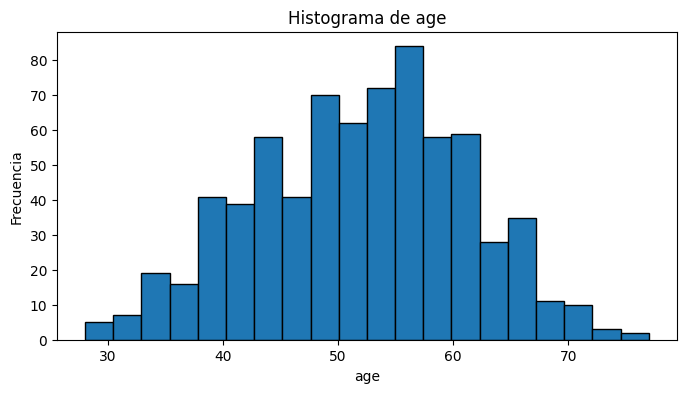

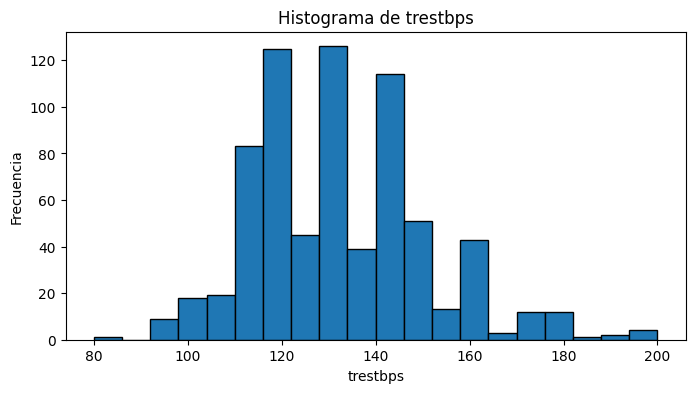

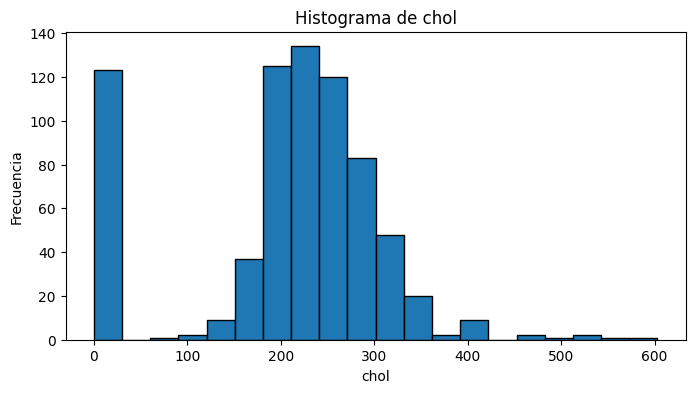

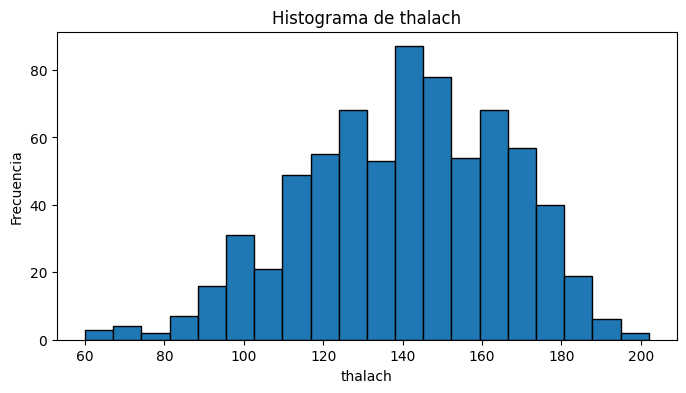

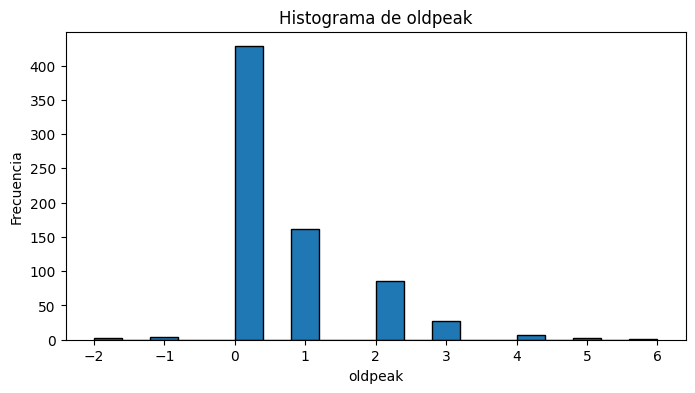

In [ ]:
# Definir las columnas continuas para los histogramas
col_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# Crear histogramas para cada columna continua
for col in col_continuas:
    plt.figure(figsize=(8,4))
    plt.hist(df_dummies[col], bins=20, edgecolor='black')
    plt.title(f'Histograma de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.show()

Index(['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak',
       'ca', 'num', 'cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2',
       'slope_2', 'slope_3', 'thal_6', 'thal_7'],
      dtype='object')


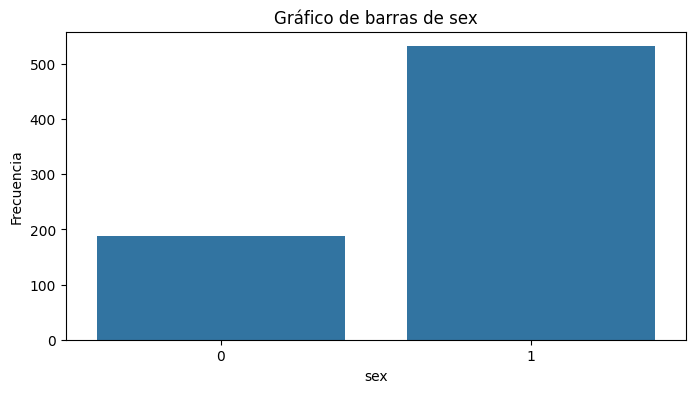

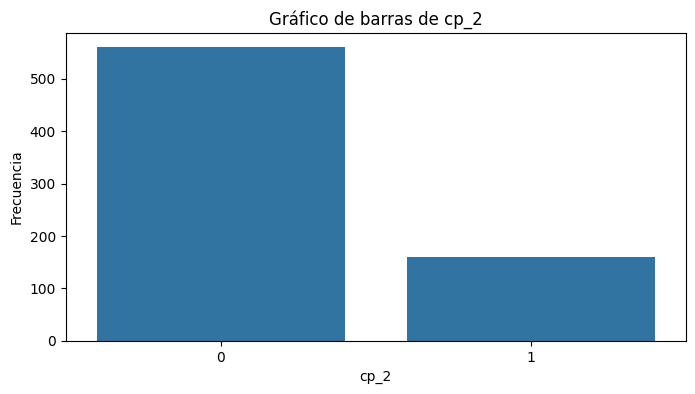

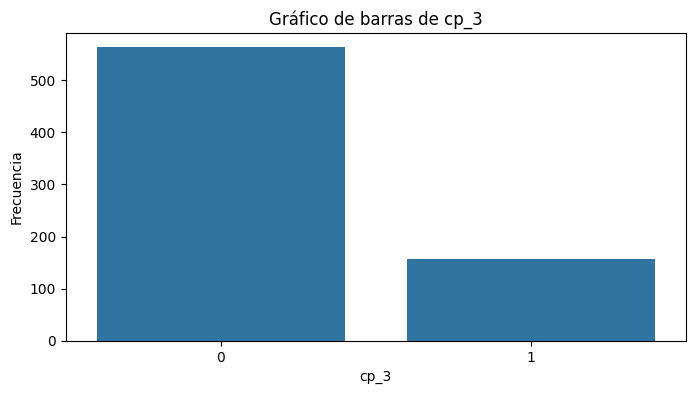

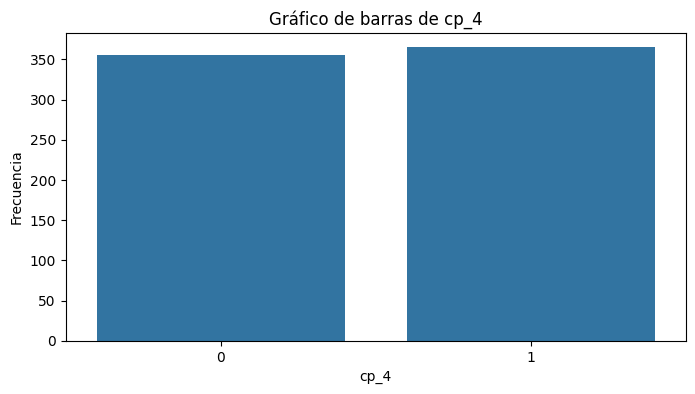

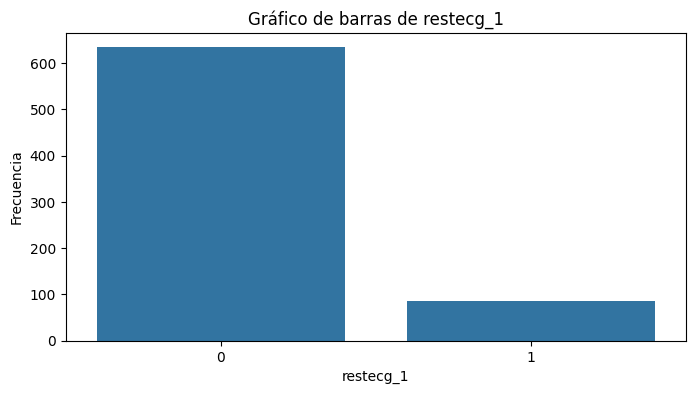

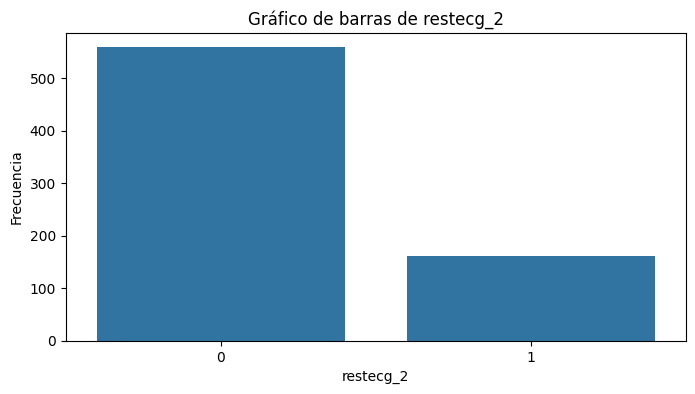

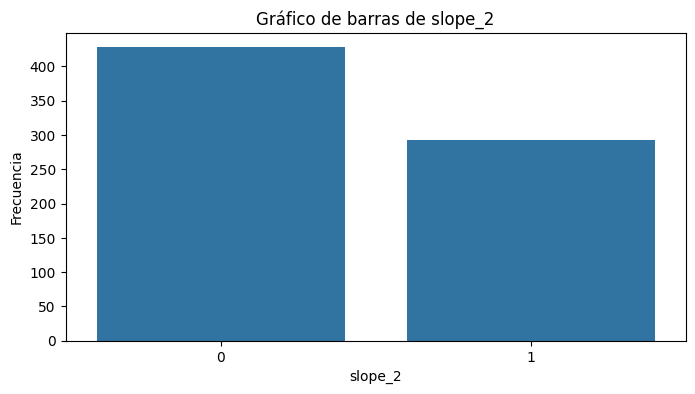

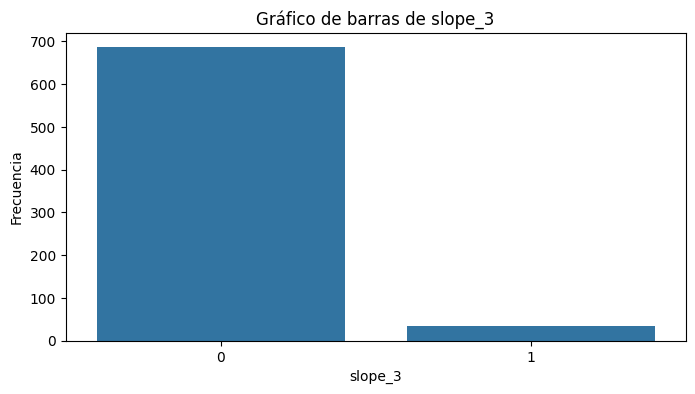

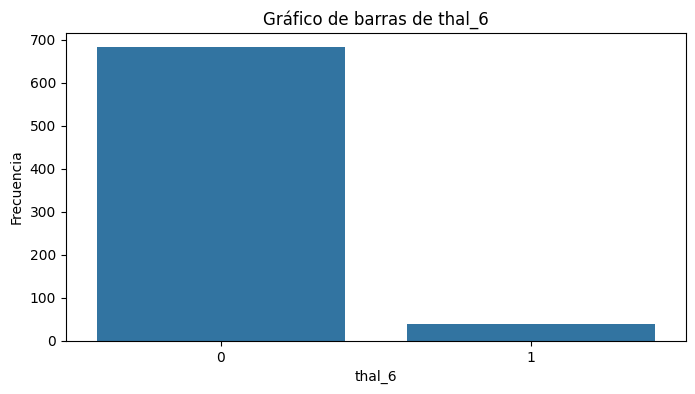

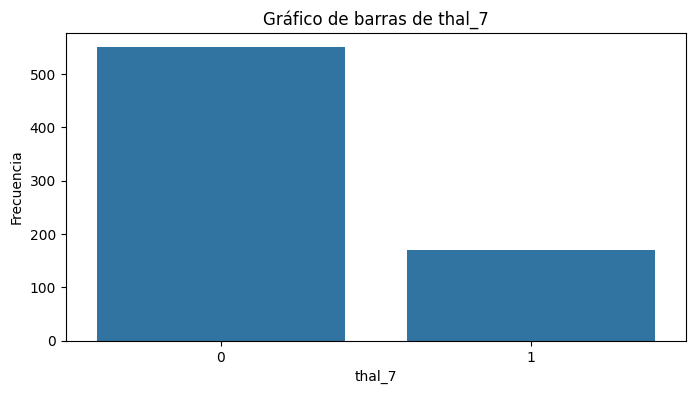

In [ ]:
# Definir las columnas categóricas para los gráficos de barras
cols_categoricas= ['sex', 'cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2',	'slope_2',	'slope_3',	'thal_6',	'thal_7']

# Verificar las columnas disponibles en df_dummies
print(df_dummies.columns)

# Crear gráficos de barras para cada columna categórica que existe en df_dummies
for col in cols_categoricas:
    if col in df_dummies.columns:  # Verificar si la columna existe antes de graficar
        plt.figure(figsize=(8, 4))
        sns.countplot(x=df_dummies[col])
        plt.title(f'Gráfico de barras de {col}')
        plt.xlabel(col)
        plt.ylabel('Frecuencia')
        plt.show()
    else:
        print(f"La columna '{col}' no se encuentra en el DataFrame.")

2. Divide la muestra en entrenamiento y test (33%), y con ello:

- a. entrena un modelo de ensamble secuencial AdaBoost
- b. entrena un modelo de ensamble secuencial Gradient Boosting
- c. entrena un modelo de ensamble secuencial XGBoosting

Para cada uno, utiliza hiper parámetros por defecto y muestra su desempeño usando las métricas adecuadas. Comenta.

In [ ]:
# Variables independientes (todas menos la columna 'num') y dependiente (la variable objetivo 'num')
X = df_dummies.drop('num', axis=1)
y = df_dummies['num']

# División de los datos en entrenamiento (67%) y test (33%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)


Ensamble secuencial AdaBoost

In [ ]:
# Entrenar el modelo AdaBoost
ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train, y_train)

# Predicciones
y_pred_ada = ada_model.predict(X_test)

# Evaluar el modelo AdaBoost
print("Desempeño del modelo AdaBoost:")
print("Accuracy:", accuracy_score(y_test, y_pred_ada))
print("Precision:", precision_score(y_test, y_pred_ada))
print("Recall:", recall_score(y_test, y_pred_ada))
print("F1 Score:", f1_score(y_test, y_pred_ada))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, y_pred_ada))
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred_ada))


Desempeño del modelo AdaBoost:
Accuracy: 0.8319327731092437
Precision: 0.8166666666666667
Recall: 0.8448275862068966
F1 Score: 0.8305084745762712

Matriz de confusión:
 [[100  22]
 [ 18  98]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.85      0.82      0.83       122
           1       0.82      0.84      0.83       116

    accuracy                           0.83       238
   macro avg       0.83      0.83      0.83       238
weighted avg       0.83      0.83      0.83       238



Ensamble secuencial Gradient Boosting

In [ ]:
# Entrenar el modelo Gradient Boosting
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# Predicciones
y_pred_gb = gb_model.predict(X_test)

# Evaluar el modelo Gradient Boosting
print("\nDesempeño del modelo Gradient Boosting:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, y_pred_gb))
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred_gb))



Desempeño del modelo Gradient Boosting:
Accuracy: 0.8529411764705882
Precision: 0.8461538461538461
Recall: 0.853448275862069
F1 Score: 0.8497854077253219

Matriz de confusión:
 [[104  18]
 [ 17  99]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.86      0.85      0.86       122
           1       0.85      0.85      0.85       116

    accuracy                           0.85       238
   macro avg       0.85      0.85      0.85       238
weighted avg       0.85      0.85      0.85       238



Ensamble secuencial XGBoost


In [ ]:
# Entrenar el modelo XGBoost
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Predicciones
y_pred_xgb = xgb_model.predict(X_test)

# Evaluar el modelo XGBoost
print("\nDesempeño del modelo XGBoost:")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred_xgb))



Desempeño del modelo XGBoost:
Accuracy: 0.8151260504201681
Precision: 0.8050847457627118
Recall: 0.8189655172413793
F1 Score: 0.811965811965812

Matriz de confusión:
 [[99 23]
 [21 95]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.82      0.81      0.82       122
           1       0.81      0.82      0.81       116

    accuracy                           0.82       238
   macro avg       0.82      0.82      0.82       238
weighted avg       0.82      0.82      0.82       238



De acuerdo con los resultados obtenidos en los distintos modelos de ensamble, se puede afirmar que el modelo con mejor desempeño del f1 score es el modelo Gradient Boosting

3. Realiza una búsqueda del hiper parámetro para el modelo que resulte tener mejor
desempeño (utiliza f1-score para determinarlo). Los valores a buscar para la grilla
son:

- a. n_estimators: 20 a 200 con 15 valores
- b. learning_rate: 0.004 a 1.0 con 40 valores
- c. sub_sample: 0.1 a 1.0 con 18 valores

Muestra los mejores hiper parámetros encontrados y entrena un modelo con estos,
presentando sus métricas.

In [ ]:
# Definir la grilla de búsqueda para los hiperparámetros
param_grid = {
    'n_estimators': np.linspace(20, 200, 15, dtype=int),
    'learning_rate': np.linspace(0.004, 1.0, 40),
    'subsample': np.linspace(0.1, 1.0, 18)
}

In [ ]:
# Inicializar el modelo de Gradient Boosting
gb_model = GradientBoostingClassifier(random_state=42)

# Configurar GridSearchCV
grid_search = GridSearchCV(estimator=gb_model,
                           param_grid=param_grid,
                           scoring='f1',
                           cv=5,  # Validación cruzada de 5 pliegues
                           verbose=2,
                           n_jobs=-1)  # Usar todos los núcleos disponibles


In [24]:
# Ejecutar la búsqueda de hiperparámetros
grid_search.fit(X_train, y_train)

# Imprimir los mejores hiperparámetros encontrados
print("Mejores hiperparámetros encontrados:", grid_search.best_params_)


Fitting 5 folds for each of 10800 candidates, totalling 54000 fits
Mejores hiperparámetros encontrados: {'learning_rate': 0.10615384615384615, 'n_estimators': 45, 'subsample': 0.47058823529411764}


In [25]:
# Entrenar el modelo con los mejores hiperparámetros
best_gb_model = grid_search.best_estimator_

# Predecir en el conjunto de prueba
y_pred_best_gb = best_gb_model.predict(X_test)

# Evaluar el rendimiento del modelo optimizado
print("\nDesempeño del modelo Gradient Boosting optimizado:")
print("Accuracy:", accuracy_score(y_test, y_pred_best_gb))
print("Precision:", precision_score(y_test, y_pred_best_gb))
print("Recall:", recall_score(y_test, y_pred_best_gb))
print("F1 Score:", f1_score(y_test, y_pred_best_gb))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, y_pred_best_gb))
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred_best_gb))



Desempeño del modelo Gradient Boosting optimizado:
Accuracy: 0.865546218487395
Precision: 0.868421052631579
Recall: 0.853448275862069
F1 Score: 0.8608695652173913

Matriz de confusión:
 [[107  15]
 [ 17  99]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.86      0.88      0.87       122
           1       0.87      0.85      0.86       116

    accuracy                           0.87       238
   macro avg       0.87      0.87      0.87       238
weighted avg       0.87      0.87      0.87       238



4. Elabora un gráfico con las curvas ROC para cada modelo entrenado, y a partir de ello
recomienda alguno de ellos. Justifica la decisión

In [28]:
# ipython-input-27-bfd4ac28e1a5
# Predecir las probabilidades para el conjunto de prueba de cada modelo
y_pred_prob_ada = ada_model.predict_proba(X_test)[:, 1]
# Use best_gb_model instead of gb_model
y_pred_prob_gb = best_gb_model.predict_proba(X_test)[:, 1]
y_pred_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [29]:
# Curvas ROC y AUC para cada modelo
fpr_ada, tpr_ada, _ = roc_curve(y_test, y_pred_prob_ada)
roc_auc_ada = auc(fpr_ada, tpr_ada)

fpr_gb, tpr_gb, _ = roc_curve(y_test, y_pred_prob_gb)
roc_auc_gb = auc(fpr_gb, tpr_gb)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_prob_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)


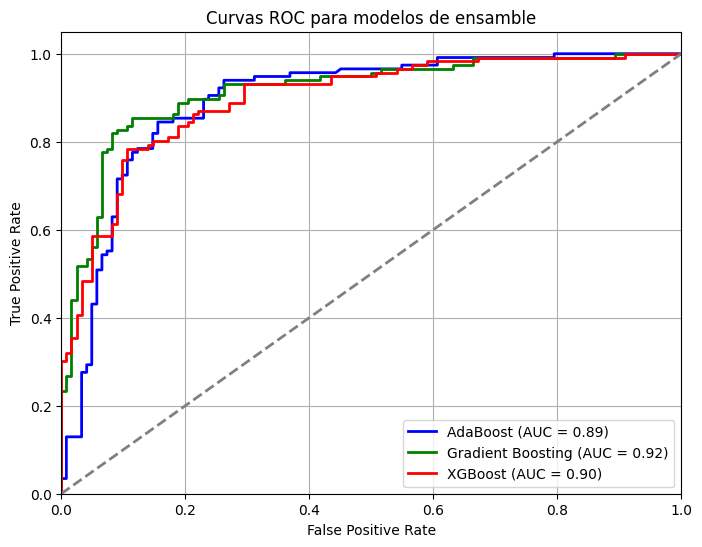

In [30]:
# Gráfico de las curvas ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr_ada, tpr_ada, color='blue', lw=2, label=f'AdaBoost (AUC = {roc_auc_ada:.2f})')
plt.plot(fpr_gb, tpr_gb, color='green', lw=2, label=f'Gradient Boosting (AUC = {roc_auc_gb:.2f})')
plt.plot(fpr_xgb, tpr_xgb, color='red', lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.2f})')

# Diagonal que representa un clasificador aleatorio
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2)

# Configuraciones del gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curvas ROC para modelos de ensamble')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


Sigue siendo el modelo con Gradient Boosting el que tiene mejor rendimiento.

5. Muestra las variables por nivel de importancia para el mejor modelo, luego de la
búsqueda de hiper parámetro. Comenta.

In [35]:
# Extraer la importancia de las variables
importances = best_gb_model.feature_importances_

# Obtener el nombre de las variables (columnas) del conjunto de datos
feature_names = X_train.columns

# Crear un DataFrame con las importancias y las variables
import pandas as pd
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Ordenar el DataFrame por importancia
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Mostrar las primeras variables más importantes
print(feature_importance_df.head(10))  # Las 10 variables más importantes


     Feature  Importance
11      cp_4    0.247393
3       chol    0.184884
6      exang    0.083560
5    thalach    0.077098
17    thal_7    0.069970
8         ca    0.065888
14   slope_2    0.053033
1        sex    0.049656
7    oldpeak    0.047955
2   trestbps    0.045977


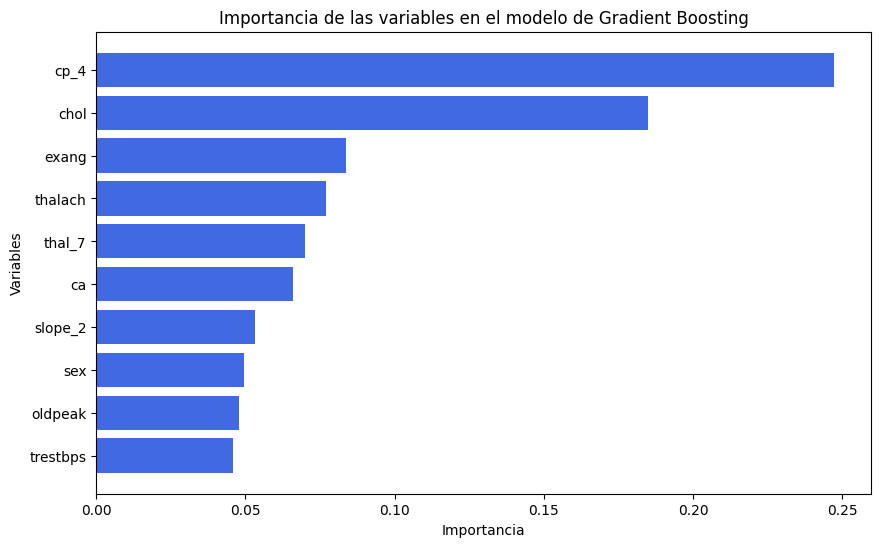

In [36]:
# Gráfico de barras de las 10 variables más importantes
import matplotlib.pyplot as plt # Import matplotlib if not already imported
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'].head(10), feature_importance_df['Importance'].head(10), color='royalblue')
plt.xlabel('Importancia')
plt.ylabel('Variables')
plt.title('Importancia de las variables en el modelo de Gradient Boosting')
plt.gca().invert_yaxis()  # Invertir el eje para que la variable más importante esté arriba
plt.show()